# Studiul de caz 5 - LLM-VaR și LLM-ES: un model de limbaj ca model al riscului de piață

Master - Rețele neuronale și deep learning (NN) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/cases/C5_llm_var')

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Pele, D. T., Bolovăneanu, V., Lin, M.-B., Ren, R., Ginavar, A. T., Spilak, B., Andrei, A.-V., Toma, F.-M., Lessmann, S. și Härdle, W. K. (2026).
In the beginning was the Word: LLM-VaR and LLM-ES. *Expert Systems with Applications*, 295, 128676. doi:10.1016/j.eswa.2025.128676

**Conținutul notebook-ului.** (1) Codificăm ultimele *w* randamente logaritmice zilnice ale indicelui S&P 500 ca un șir de numere, ca în cadrul LLMTime pe care se sprijină lucrarea.
(2) Cerem unui model lingvistic mare (LLM, *large language model*) deschis, Qwen2.5 cu 1,5 și 3 miliarde de parametri, rulat local, să *continue* șirul; extragem 1.024 de continuări pentru fiecare zi.
(3) Cuantila empirică a randamentelor simulate pentru ziua următoare este LLM-VaR (valoarea la risc, *Value-at-Risk*), iar media pierderilor de dincolo de ea este LLM-ES (pierderea așteptată în coada distribuției, *Expected Shortfall*).
(4) Testăm retrospectiv aceste estimări față de simularea istorică, EWMA (media mobilă ponderată exponențial), GARCH(1,1) (heteroscedasticitate condiționată autoregresivă generalizată) cu inovații Student-t și simularea istorică filtrată:
frecvența depășirilor, testele Kupiec și Christoffersen, semaforul Basel, funcția de pierdere pentru cuantile, funcția de pierdere FZ0 (Fissler-Ziegel) pentru perechea (VaR, ES) și testele Diebold-Mariano.

**Adaptarea pentru curs și extinderea perioadei.** Lucrarea interoghează trei generații de modele GPT (*generative pre-trained transformer*) printr-o interfață comercială, pe nouă indici
(criptomonede, acțiuni, obligațiuni, mărfuri), octombrie 2021 - martie 2024, cu ferestre de 30 pînă la 150 de zile. Noi folosim două modele deschise de mici dimensiuni, rulate pe un laptop, un singur indice (S&P 500),
două ferestre (30 și 120 de zile) și o perioadă de test recentă (noiembrie 2024 - noiembrie 2026).

## 1. Datele: randamentele logaritmice zilnice ale indicelui S&P 500

In [3]:
import torch                                   # imported before scipy/arch (course rule: torch first)
from scipy import stats
from arch import arch_model
import copy, json, time, matplotlib.dates as mdates
px = cu.markets_daily()["SP500"].dropna()
r = (100 * np.log(px).diff()).dropna()         # daily log return, in percent
TEST0 = "2024-11-01"
TD = r.loc[TEST0:].index                         # test days: one-day-ahead forecasts, information up to the previous close
n_test = len(TD)
print(f"S&P 500 returns {r.index[0]:%Y-%m-%d} - {r.index[-1]:%Y-%m-%d}: {len(r)} days; test {TD[0]:%Y-%m-%d} - {TD[-1]:%Y-%m-%d}: {n_test} days")
print(r.loc[TD].describe().round(3))
os.makedirs("cache", exist_ok=True)

MON = {"en": ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
       "ro": ["ian.", "feb.", "mar.", "apr.", "mai", "iun.", "iul.", "aug.", "sep.", "oct.", "nov.", "dec."]}
def month_axis(ax, lang, step=3):
    """Month ticks with the full four-digit year, month names in the language of the chart."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1, 13, step)))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: (lambda d: f"{MON[lang][d.month - 1]} {d.year}")(mdates.num2date(v))))

S&P 500 returns 2005-01-04 - 2026-11-06: 5496 days; test 2024-11-01 - 2026-11-06: 505 days
count    505.000
mean       0.051
std        1.030
min       -6.161
25%       -0.389
50%        0.092
75%        0.577
max        9.089
Name: SP500, dtype: float64


## 2. LLM-VaR și LLM-ES: modelul de limbaj continuă seria randamentelor

Codificarea urmează cadrul LLMTime (Gruver et al., 2023), cu setările raportate pentru lucrare (baza 10, precizia 2, `time_sep=", "`, scalare cu alpha = 0,95, beta = 0,3, temperatura 0,7):
fereastra este translatată cu `min - beta * (max - min)` și împărțită la cuantila sa de 95 %, astfel încît fiecare valoare este un număr pozitiv scris cu două zecimale, fără virgulă zecimală.
Varianta principală (`text`): șirul de numere este continuat ca text simplu, așa cum procedează LLMTime pentru GPT-3 și GPT-3.5 cu aceste setări de scalare. Pentru comparație (`chat`), același șir este inclus în promptul cu instrucțiuni folosit de LLMTime pentru modelele conversaționale. Generarea este restrînsă la cifre și la virgulă (așa cum face LLMTime cu o penalizare a celorlalte simboluri) și se oprește la prima virgulă.
Promptul este procesat o singură dată; memoria sa cheie-valoare este copiată de 256 de ori la fiecare trecere (patru treceri), iar numărul următor este eșantionat simbol cu simbol. Semințele: `torch.manual_seed(20261108 + zi)`.

*Timpul de rulare*: aproximativ 2-3 s pe zi și pe model pe un Apple M5 Max (MPS, precizie redusă la jumătate); cele cinci configurații durează în total aproximativ o oră și jumătate. Rezultatele sînt salvate în `cache/`; ștergeți un fișier pentru a-l recalcula.

In [4]:
# (model, window, prompt): "text" = the serialised series is continued as plain text (LLMTime setting for GPT-3/GPT-3.5 with alpha = 0.95, beta = 0.3);
# "chat" = the same series inside the LLMTime instruction prompt for chat models (shown for comparison)
CONF = [("Qwen/Qwen2.5-1.5B-Instruct", 30, "text"), ("Qwen/Qwen2.5-1.5B-Instruct", 120, "text"), ("Qwen/Qwen2.5-3B-Instruct", 30, "text"),
        ("Qwen/Qwen2.5-3B-Instruct", 120, "text"), ("Qwen/Qwen2.5-3B-Instruct", 30, "chat")]
NSAMP, TEMP, ALPHA_S, BETA_S, PREC = 1024, 0.7, 0.95, 0.3, 2
LEVELS = [0.01, 0.025, 0.05]
SYS = ("You are a helpful assistant that performs time series predictions. The user will provide a sequence and you will predict the "
       "remaining sequence. The sequence is represented by decimal strings separated by commas.")
USR = ("Please continue the following sequence without producing any additional text. Do not say anything like 'the next terms in the "
       "sequence are', just return the numbers. Sequence:\n")
tag = lambda name, w, mode: f"{name.split('-')[1].lower()}_w{w}_{mode}"          # e.g. 1.5b_w30_text -> file name
short = lambda name: name.split("/")[1].replace("-Instruct", "")
_LM = {}

def load_lm(name):
    from transformers import AutoTokenizer, AutoModelForCausalLM
    if name not in _LM:
        dev = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
        tok = AutoTokenizer.from_pretrained(name)
        m = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float16 if dev != "cpu" else torch.float32).to(dev).eval()
        _LM[name] = (tok, m, dev)
    return _LM[name]

def encode(hist):
    """LLMTime scaling: shift by min - beta*(max - min), divide by the alpha-quantile; values written with PREC digits, no decimal point."""
    mn = hist.min() - BETA_S * (hist.max() - hist.min())
    q = np.quantile(hist - mn, ALPHA_S)
    z = (hist - mn) / q
    return ", ".join(str(int(round(v * 10 ** PREC))) for v in z), mn, q

@torch.no_grad()
def sample_next(name, hist, mode="text", n=NSAMP, seed=0, chunk=256):
    """n sampled continuations (one number each) of the encoded window -> n simulated next-day returns (%).
    The prompt is processed once; its key-value cache is copied `chunk` times per pass (memory), n/chunk passes."""
    tok, m, dev = load_lm(name)
    s, mn, q = encode(hist)
    if mode == "chat":
        txt = tok.apply_chat_template([{"role": "system", "content": SYS}, {"role": "user", "content": USR + s}], tokenize=False, add_generation_prompt=True)
    else:
        txt = s + ", "                                                  # plain continuation of the number string
    ids = tok(txt, return_tensors="pt", add_special_tokens=False).input_ids.to(dev)
    torch.manual_seed(seed)
    out = m(ids, use_cache=True)
    V = out.logits.shape[-1]
    dig = [tok.convert_tokens_to_ids(str(d)) for d in range(10)]
    comma = tok.encode(",", add_special_tokens=False)[0]
    m_dig = torch.full((V,), float("-inf"), device=dev); m_dig[dig] = 0
    m_first = m_dig.clone(); m_first[dig[0]] = float("-inf")           # no leading zero
    m_end = m_dig.clone(); m_end[comma] = 0
    m_comma = torch.full((V,), float("-inf"), device=dev); m_comma[comma] = 0
    lut = torch.full((V,), -1, dtype=torch.long, device=dev); lut[dig] = torch.arange(10, device=dev)
    vals = []
    for _ in range(n // chunk):
        cache = copy.deepcopy(out.past_key_values)
        cache.batch_repeat_interleave(chunk)                            # one prompt, `chunk` continuations
        logits = out.logits[:, -1, :].float().expand(chunk, -1)
        val = torch.zeros(chunk, dtype=torch.long, device=dev); done = torch.zeros(chunk, dtype=torch.bool, device=dev)
        for step in range(4):                                           # 2 or 3 digits, then the comma
            mask = m_first if step == 0 else m_dig if step == 1 else m_end if step == 2 else m_comma
            nxt = torch.multinomial(torch.softmax((logits + mask) / TEMP, -1), 1).squeeze(1)
            d = lut[nxt]
            upd = (d >= 0) & ~done
            val = torch.where(upd, val * 10 + d.clamp(min=0), val)
            done = done | (d < 0)
            if done.all() or step == 3:
                break
            o = m(nxt[:, None], past_key_values=cache, use_cache=True)
            cache, logits = o.past_key_values, o.logits[:, -1, :].float()
        vals.append(val.cpu().numpy())
        del cache
    return np.concatenate(vals) / 10 ** PREC * q + mn

def summarise(y):
    row = {"mean": y.mean(), "sd": y.std()}
    for a in LEVELS:
        qa = np.quantile(y, a)
        row[f"q{a}"] = qa
        row[f"es{a}"] = y[y <= qa].mean()
    return row

def llm_run(name, w, mode):
    path = os.path.join("cache", f"llm_{tag(name, w, mode)}.csv")
    if os.path.exists(path):
        return pd.read_csv(path, index_col=0, parse_dates=True)
    t0, rows = time.time(), []
    for k, d in enumerate(TD):
        i = r.index.get_loc(d)
        rows.append(summarise(sample_next(name, r.values[i - w:i], mode, seed=20261108 + k)))
        if k % 100 == 99:
            print(f"  {short(name)} w={w} {mode}: {k + 1} days, {(time.time() - t0) / (k + 1):.2f} s per day", flush=True)
    out = pd.DataFrame(rows, index=TD)
    out.to_csv(path, float_format="%.5f")
    print(f"{short(name)} w={w} {mode}: {len(TD)} days in {(time.time() - t0) / 60:.1f} min")
    return out

LLM = {(short(nm), w, md): llm_run(nm, w, md) for nm, w, md in CONF}
# one illustrative day (largest loss of the test period): keep all 1,024 samples of the main configuration
d_ex = r.loc[TD].idxmin()
ex_path = os.path.join("cache", "example_day_samples.json")
if not os.path.exists(ex_path):
    i = r.index.get_loc(d_ex)
    json.dump({"date": f"{d_ex:%Y-%m-%d}", "samples": [round(float(v), 4) for v in sample_next(CONF[2][0], r.values[i - 30:i], "text", seed=20261108 + TD.get_loc(d_ex))]},
              open(ex_path, "w"))
EX = json.load(open(ex_path))
print("largest test-period loss:", EX["date"], f"{r.loc[d_ex]:.2f} %")
for k, v in LLM.items():
    print(k, f"mean 1 % quantile {v['q0.01'].mean():.2f}, mean sd of the samples {v['sd'].mean():.2f}")

largest test-period loss: 2025-04-04 -6.16 %
('Qwen2.5-1.5B', 30, 'text') mean 1 % quantile -2.30, mean sd of the samples 0.98
('Qwen2.5-1.5B', 120, 'text') mean 1 % quantile -1.98, mean sd of the samples 0.81
('Qwen2.5-3B', 30, 'text') mean 1 % quantile -2.01, mean sd of the samples 0.86
('Qwen2.5-3B', 120, 'text') mean 1 % quantile -1.81, mean sd of the samples 0.77
('Qwen2.5-3B', 30, 'chat') mean 1 % quantile -1.76, mean sd of the samples 0.96


## 3. Reperele clasice

In [5]:
z = {a: stats.norm.ppf(a) for a in LEVELS}
BM = {}
# historical simulation, 250 days
hs = pd.DataFrame(index=TD)
for a in LEVELS:
    qs, es = [], []
    for d in TD:
        i = r.index.get_loc(d); h = r.values[i - 250:i]; q_ = np.quantile(h, a)
        qs.append(q_); es.append(h[h <= q_].mean())
    hs[f"q{a}"], hs[f"es{a}"] = qs, es
BM["HS (250 days)"] = hs
# EWMA (RiskMetrics, lambda = 0.94), normal innovations, zero mean
lam = 0.94
s2 = np.empty(len(r)); s2[0] = r.values[:30].var()
for t in range(1, len(r)):
    s2[t] = lam * s2[t - 1] + (1 - lam) * r.values[t - 1] ** 2
sig = pd.Series(np.sqrt(s2), index=r.index).loc[TD]
ew = pd.DataFrame(index=TD)
for a in LEVELS:
    ew[f"q{a}"] = sig * z[a]
    ew[f"es{a}"] = -sig * stats.norm.pdf(z[a]) / a
BM["EWMA-N"] = ew
# GARCH(1,1)-t and filtered historical simulation (GARCH(1,1)-N residuals), 1,000-day rolling window, re-estimated every day
gpath = os.path.join("cache", "garch_benchmarks.csv")
if os.path.exists(gpath):
    G = pd.read_csv(gpath, index_col=0, parse_dates=True)
else:
    rows = []
    for d in TD:
        i = r.index.get_loc(d); h = r.values[i - 1000:i]
        ft = arch_model(h, mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False).fit(disp="off", show_warning=False)
        f = ft.forecast(horizon=1, reindex=False)
        mu, s2t, nu = float(f.mean.values[-1, 0]), float(f.variance.values[-1, 0]), float(ft.params["nu"])
        sc = np.sqrt(s2t * (nu - 2) / nu)
        row = {"nu": nu}
        for a in LEVELS:
            ta = stats.t.ppf(a, nu)
            row[f"gt_q{a}"] = mu + sc * ta
            row[f"gt_es{a}"] = mu - sc * stats.t.pdf(ta, nu) * (nu + ta ** 2) / ((nu - 1) * a)
        fn = arch_model(h, mean="Constant", vol="GARCH", p=1, q=1, dist="normal", rescale=False).fit(disp="off", show_warning=False)
        zr = fn.std_resid
        fc = fn.forecast(horizon=1, reindex=False)
        mu_n, s_n = float(fc.mean.values[-1, 0]), float(np.sqrt(fc.variance.values[-1, 0]))
        for a in LEVELS:
            qz = np.quantile(zr, a)
            row[f"fhs_q{a}"] = mu_n + s_n * qz
            row[f"fhs_es{a}"] = mu_n + s_n * zr[zr <= qz].mean()
        rows.append(row)
    G = pd.DataFrame(rows, index=TD); G.to_csv(gpath, float_format="%.5f")
BM["GARCH(1,1)-t"] = G[[c for c in G if c.startswith("gt_")]].rename(columns=lambda c: c[3:])
BM["Filtered HS"] = G[[c for c in G if c.startswith("fhs_")]].rename(columns=lambda c: c[4:])
print("mean Student-t degrees of freedom: %.1f" % G["nu"].mean())

mean Student-t degrees of freedom: 7.4


## 4. Testarea retrospectivă

Pentru un nivel $\alpha$, indicatorul de depășire este $I_t=\mathbb 1\{r_t<q_t\}$, unde $q_t=-\mathrm{VaR}_t$ este cuantila prognozată a randamentului.
Kupiec: $LR_{uc}=-2\ln\frac{(1-\alpha)^{n_0}\alpha^{n_1}}{(1-\hat\pi)^{n_0}\hat\pi^{n_1}}\sim\chi^2_1$; Christoffersen: $LR_{ind}\sim\chi^2_1$ din numărul de tranziții $n_{ij}$, $LR_{cc}=LR_{uc}+LR_{ind}\sim\chi^2_2$.
Funcția de pierdere pentru cuantile $(\alpha-I_t)(r_t-q_t)$; funcția FZ0 pentru $(q_t,e_t)$: $-\frac{1}{\alpha e_t}I_t(q_t-r_t)+\frac{q_t}{e_t}+\ln(-e_t)-1$.

In [6]:
def kupiec(h, a):
    n, x = len(h), int(h.sum()); p = x / n
    ll0 = (n - x) * np.log(1 - a) + x * np.log(a)
    ll1 = (n - x) * np.log(1 - p) + (x * np.log(p) if x > 0 else 0)
    return float(stats.chi2.sf(-2 * (ll0 - ll1), 1)), -2 * (ll0 - ll1)

def christoffersen(h, a):
    h = h.astype(int); a0, a1 = h[:-1], h[1:]
    n00, n01 = int(((a0 == 0) & (a1 == 0)).sum()), int(((a0 == 0) & (a1 == 1)).sum())
    n10, n11 = int(((a0 == 1) & (a1 == 0)).sum()), int(((a0 == 1) & (a1 == 1)).sum())
    p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1); p = (n01 + n11) / max(n00 + n01 + n10 + n11, 1)
    L = lambda x, k: k * np.log(x) if k > 0 else 0.0
    ll_ind = L(1 - p01, n00) + L(p01, n01) + L(1 - p11, n10) + L(p11, n11)
    ll_0 = L(1 - p, n00 + n10) + L(p, n01 + n11)
    lr_ind = -2 * (ll_0 - ll_ind)
    lr_uc = kupiec(h, a)[1]
    return float(stats.chi2.sf(lr_ind, 1)), float(stats.chi2.sf(lr_uc + lr_ind, 2))

def zone(x):            # Basel traffic light for 250 days of 1 % VaR
    return "green" if x <= 4 else ("yellow" if x <= 9 else "red")
PLUS = {5: 0.40, 6: 0.50, 7: 0.65, 8: 0.75, 9: 0.85}
plus = lambda x: 0.0 if x <= 4 else PLUS.get(x, 1.0)

tick = lambda y, q, a: (a - (y < q)) * (y - q)
def fz0(y, q, e, a):
    return -1 / (a * e) * (y < q) * (q - y) + q / e + np.log(-e) - 1

def dm(l1, l2, lag=5):
    """Diebold-Mariano test of equal mean loss, Newey-West variance; negative statistic = model 1 better."""
    d = np.asarray(l1) - np.asarray(l2); n = len(d); dc = d - d.mean()
    v = dc @ dc / n + 2 * sum((1 - k / (lag + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, lag + 1))
    s = d.mean() / np.sqrt(v / n)
    return s, 2 * stats.norm.sf(abs(s))

y = r.loc[TD].values
MODELS = {f"LLM-VaR {k[0]}, w = {k[1]}" + (", chat" if k[2] == "chat" else ""): v for k, v in LLM.items()}
MODELS.update(BM)
MAIN, REF = "LLM-VaR Qwen2.5-3B, w = 30", "GARCH(1,1)-t"
rows, LOSS = {}, {}
for nm, f in MODELS.items():
    h1 = y < f["q0.01"].values; h25 = y < f["q0.025"].values
    pu, _ = kupiec(h1, 0.01); pi, pc = christoffersen(h1, 0.01)
    x250 = int(h1[-250:].sum())
    LOSS[nm] = {"tick": tick(y, f["q0.01"].values, 0.01), "fz": fz0(y, f["q0.025"].values, f["es0.025"].values, 0.025)}
    rows[nm] = {"viol": int(h1.sum()), "rate": 100 * h1.mean(), "puc": pu, "pind": pi, "pcc": pc, "var": -f["q0.01"].mean(),
                "viol25": int(h25.sum()), "rate25": 100 * h25.mean(), "es": -f["es0.025"].mean(), "x250": x250, "zone": zone(x250),
                "tick": LOSS[nm]["tick"].mean(), "fz": LOSS[nm]["fz"].mean()}
res = pd.DataFrame(rows).T
for nm in MODELS:
    s_, p_ = dm(LOSS[nm]["fz"], LOSS[REF]["fz"]) if nm != REF else (np.nan, np.nan)
    res.loc[nm, "dm"], res.loc[nm, "dmp"] = s_, p_
num = ["viol", "rate", "puc", "pind", "pcc", "var", "viol25", "rate25", "es", "x250", "tick", "fz", "dm", "dmp"]
res[num] = res[num].astype(float)
print(f"expected 1 % violations: {0.01 * n_test:.1f};  2.5 %: {0.025 * n_test:.1f}")
show = res[["viol", "rate", "puc", "pind", "pcc", "var", "rate25", "es", "x250", "zone", "tick", "fz", "dm", "dmp"]]
show

expected 1 % violations: 5.0;  2.5 %: 12.6


,viol,rate,puc,pind,pcc,var,rate25,es,x250,zone,tick,fz,dm,dmp
"LLM-VaR Qwen2.5-1.5B, w = 30",11.0,2.178218,2.134687e-02,2.293503e-01,3.433577e-02,2.304249,3.366337,2.269917,5.0,yellow,0.046501,1.391073,1.414210,0.157300
"LLM-VaR Qwen2.5-1.5B, w = 120",12.0,2.376238,8.291032e-03,2.800287e-01,1.710766e-02,1.981638,6.138614,2.005254,6.0,yellow,0.044958,1.333580,0.983629,0.325298
"LLM-VaR Qwen2.5-3B, w = 30",16.0,3.168317,9.447568e-05,5.256584e-01,4.002601e-04,2.013322,4.752475,1.989954,10.0,red,0.047658,1.426524,1.664650,0.095983
"LLM-VaR Qwen2.5-3B, w = 120",13.0,2.574257,2.993080e-03,3.353998e-01,7.674830e-03,1.807886,7.326733,1.829251,6.0,yellow,0.050077,1.539466,1.843999,0.065183
"LLM-VaR Qwen2.5-3B, w = 30, chat",64.0,12.673267,1.508894e-48,7.092838e-11,1.648349e-56,1.764633,18.019802,1.695776,35.0,red,0.179607,NaN,NaN,NaN
HS (250 days),8.0,1.584158,2.240417e-01,1.079411e-01,1.311778e-01,2.618399,2.970297,2.844064,3.0,green,0.049305,1.248905,0.215832,0.829118
EWMA-N,11.0,2.178218,2.134687e-02,2.293503e-01,3.433577e-02,2.138859,3.762376,2.149391,4.0,green,0.048926,1.309017,1.960859,0.049895
"GARCH(1,1)-t",11.0,2.178218,2.134687e-02,2.293503e-01,3.433577e-02,2.283724,2.970297,2.352202,4.0,green,0.046260,1.214424,NaN,NaN
Filtered HS,10.0,1.980198,5.085296e-02,1.836544e-01,6.139324e-02,2.383761,2.376238,2.592574,4.0,green,0.045331,1.158220,-1.112112,0.266090


In [7]:
LAB = {nm: (nm, nm.replace("HS (250 days)", "HS (250 de zile)").replace(", chat", ", conversațional")) for nm in MODELS}
LAB["Filtered HS"] = ("Filtered HS", "HS filtrată")
t1 = res[["viol", "rate", "puc", "pind", "pcc", "var"]].copy()
t1.index = [LAB[i] for i in t1.index]
cu.write_table(t1, "backtest", [("Model", "Model"), ("Viol.", "Dep."), ("Rate (\\%)", "Rata (\\%)"), ("$p_{uc}$", "$p_{uc}$"),
                                 ("$p_{ind}$", "$p_{ind}$"), ("$p_{cc}$", "$p_{cc}$"), ("VaR 1\\,\\%", "VaR 1\\,\\%")],
               digits={"viol": 0, "rate": 2, "puc": 3, "pind": 3, "pcc": 3, "var": 2}, best={"puc": "max", "pcc": "max"})
t2 = res[["rate25", "es", "tick", "fz", "dm", "dmp"]].copy()
t2.index = [LAB[i] for i in t2.index]
cu.write_table(t2, "loss", [("Model", "Model"), ("Viol.\\ 2.5\\,\\% (\\%)", "Dep.\\ 2,5\\,\\% (\\%)"), ("ES 2.5\\,\\%", "ES 2,5\\,\\%"),
                             ("Tick loss", "Pierdere cuantilă"), ("FZ0 loss", "Pierdere FZ0"), ("DM", "DM"), ("$p_{DM}$", "$p_{DM}$")],
               digits={"rate25": 2, "es": 2, "tick": 4, "fz": 3, "dm": 2, "dmp": 3}, best={"tick": "min", "fz": "min"})
cu.show_table(t2.astype(float), best={"tick": "min", "fz": "min"}, digits=3)

,rate25,es,tick,fz,dm,dmp
"('LLM-VaR Qwen2.5-1.5B, w = 30', 'LLM-VaR Qwen2.5-1.5B, w = 30')",3.366,2.270,0.047,1.391,1.414,0.157
"('LLM-VaR Qwen2.5-1.5B, w = 120', 'LLM-VaR Qwen2.5-1.5B, w = 120')",6.139,2.005,0.045,1.334,0.984,0.325
"('LLM-VaR Qwen2.5-3B, w = 30', 'LLM-VaR Qwen2.5-3B, w = 30')",4.752,1.990,0.048,1.427,1.665,0.096
"('LLM-VaR Qwen2.5-3B, w = 120', 'LLM-VaR Qwen2.5-3B, w = 120')",7.327,1.829,0.050,1.539,1.844,0.065
"('LLM-VaR Qwen2.5-3B, w = 30, chat', 'LLM-VaR Qwen2.5-3B, w = 30, conversațional')",18.020,1.696,0.180,nan,nan,nan
"('HS (250 days)', 'HS (250 de zile)')",2.970,2.844,0.049,1.249,0.216,0.829
"('EWMA-N', 'EWMA-N')",3.762,2.149,0.049,1.309,1.961,0.050
"('GARCH(1,1)-t', 'GARCH(1,1)-t')",2.970,2.352,0.046,1.214,nan,nan
"('Filtered HS', 'HS filtrată')",2.376,2.593,0.045,1.158,-1.112,0.266


## 5. Grafice

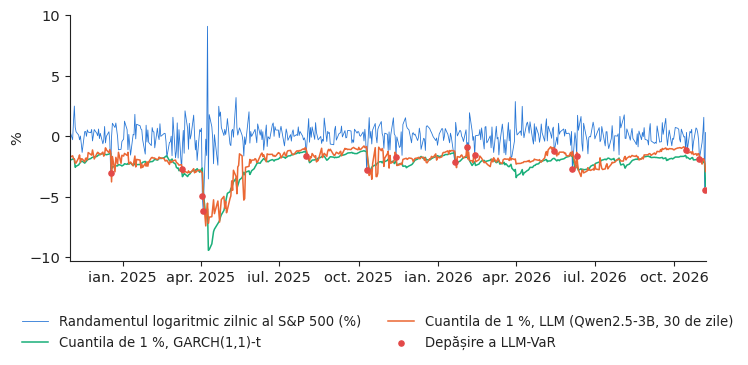

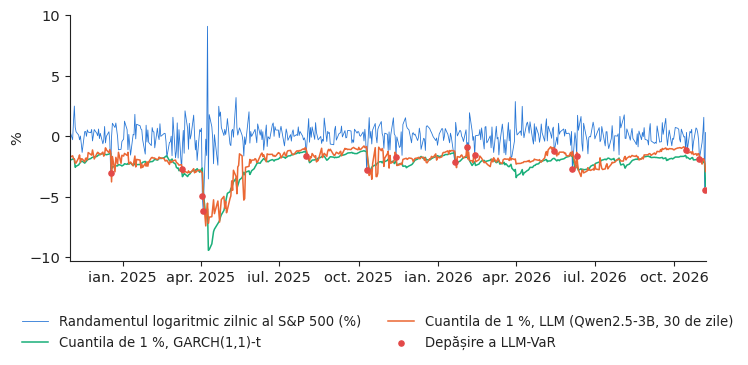

In [8]:
C_LLM, C_BM, C_DATA = cu.PAL["DE_LU"], cu.PAL["HU"], cu.PAL["RO"]
f_main, f_ref = MODELS[MAIN], MODELS[REF]
hit = y < f_main["q0.01"].values
def fig_path(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.2))
    ax.plot(TD, y, color=C_DATA, lw=0.6, label=cu.T(lang, "S&P 500 daily log return (%)", "Randamentul logaritmic zilnic al S&P 500 (%)"))
    ax.plot(TD, f_ref["q0.01"], color=C_BM, lw=1.1, label=cu.T(lang, "1 % quantile, GARCH(1,1)-t", "Cuantila de 1 %, GARCH(1,1)-t"))
    ax.plot(TD, f_main["q0.01"], color=C_LLM, lw=1.1, label=cu.T(lang, "1 % quantile, LLM (Qwen2.5-3B, 30 days)", "Cuantila de 1 %, LLM (Qwen2.5-3B, 30 de zile)"))
    ax.scatter(TD[hit], y[hit], s=14, color=cu.EVENT, zorder=3, label=cu.T(lang, "Violation of the LLM-VaR", "Depășire a LLM-VaR"))
    ax.set_ylabel("%"); ax.set_xlim(TD[0], TD[-1]); month_axis(ax, lang)
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_path, "f1_var_path", headline=True)

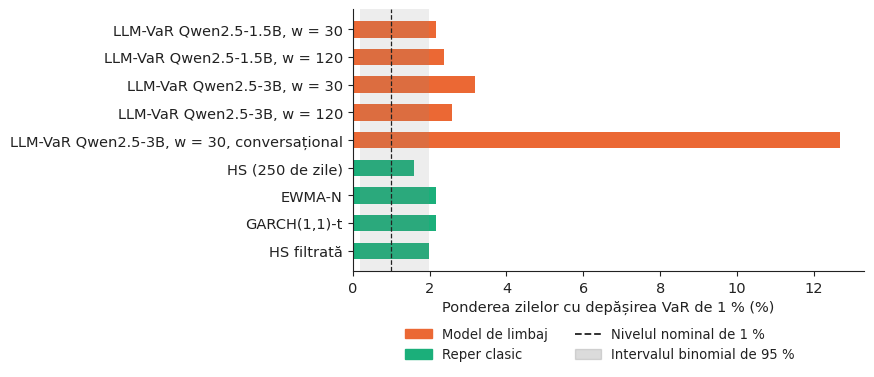

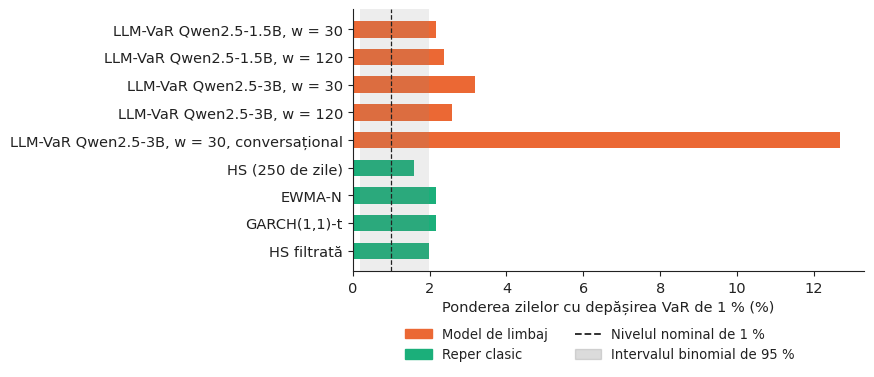

In [9]:
order = list(MODELS)
lo, hi = stats.binom.ppf(0.025, n_test, 0.01) / n_test * 100, stats.binom.ppf(0.975, n_test, 0.01) / n_test * 100
def fig_rates(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.4))
    yy = np.arange(len(order))[::-1]
    ax.barh(yy, res.loc[order, "rate"], color=[C_LLM if o.startswith("LLM") else C_BM for o in order], height=0.6)
    ax.axvspan(lo, hi, color=cu.MUTED, alpha=0.15, lw=0)
    ax.axvline(1, color=cu.INK, ls="--", lw=0.9)
    ax.set_yticks(yy); ax.set_yticklabels([cu.T(lang, *LAB[o]) for o in order])
    ax.set_xlabel(cu.T(lang, "Share of days with a 1 % VaR violation (%)", "Ponderea zilelor cu depășirea VaR de 1 % (%)"))
    cu.comma_axis(ax, lang, "x")
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    hd = [Patch(color=C_LLM), Patch(color=C_BM), Line2D([], [], color=cu.INK, ls="--"), Patch(color=cu.MUTED, alpha=0.3)]
    lb = [cu.T(lang, "Language model", "Model de limbaj"), cu.T(lang, "Classical benchmark", "Reper clasic"), cu.T(lang, "Nominal 1 %", "Nivelul nominal de 1 %"),
          cu.T(lang, "95 % binomial range", "Intervalul binomial de 95 %")]
    cu.legend_bottom(fig, ncol=2, handles=hd, labels=lb)
    return fig
cu.save_both(fig_rates, "f2_violation_rates")

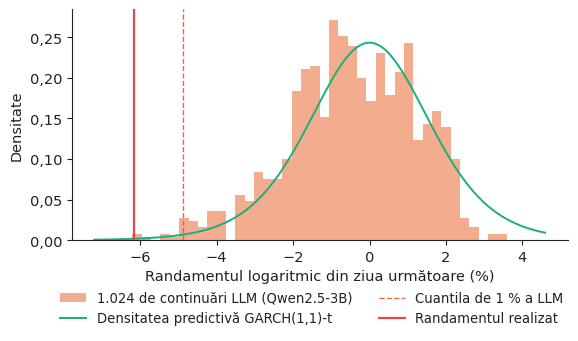

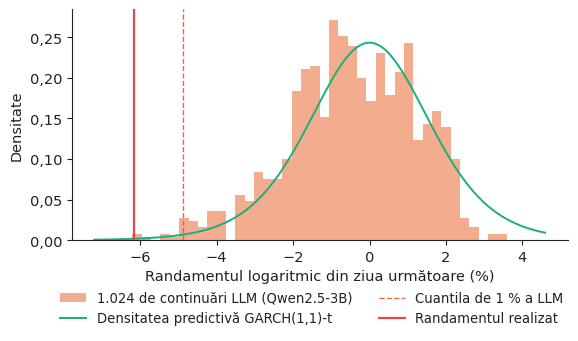

In [10]:
smp = np.array(EX["samples"]); d_ex = pd.Timestamp(EX["date"])
g = G.loc[d_ex]; nu = g["nu"]
def fig_pred(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.0))
    ax.hist(smp, bins=40, density=True, color=C_LLM, alpha=0.55, label=cu.T(lang, "1,024 LLM continuations (Qwen2.5-3B)", "1.024 de continuări LLM (Qwen2.5-3B)"))
    # GARCH-t predictive density, recovered from its 1 % quantile and degrees of freedom
    sc = (g["gt_q0.01"] - 0) / stats.t.ppf(0.01, nu)
    xs = np.linspace(min(smp.min(), r.loc[d_ex]) - 1, smp.max() + 1, 400)
    ax.plot(xs, stats.t.pdf(xs / sc, nu) / sc, color=C_BM, lw=1.4, label=cu.T(lang, "GARCH(1,1)-t predictive density", "Densitatea predictivă GARCH(1,1)-t"))
    ax.axvline(np.quantile(smp, 0.01), color=C_LLM, ls="--", lw=1, label=cu.T(lang, "LLM 1 % quantile", "Cuantila de 1 % a LLM"))
    ax.axvline(r.loc[d_ex], color=cu.EVENT, lw=1.6, label=cu.T(lang, "Realised return", "Randamentul realizat"))
    ax.set_xlabel(cu.T(lang, "Next-day log return (%)", "Randamentul logaritmic din ziua următoare (%)"))
    ax.set_ylabel(cu.T(lang, "Density", "Densitate"))
    cu.comma_axis(ax, lang, "x"); cu.comma_axis(ax, lang, "y")
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_pred, "f3_predictive")

## 6. Implicațiile testării retrospective asupra capitalului: semaforul Basel

Capitalul pentru riscul de piață în abordarea bazată pe modele interne (Comitetul de la Basel pentru Supraveghere Bancară, 1996) este $(3+k)\cdot\overline{\mathrm{VaR}}_{60}\cdot\sqrt{10}$,
media pe 60 de zile a VaR de 1 % pentru o zi, scalată la zece zile, cu factorul suplimentar $k$ stabilit de depășirile din ultimele 250 de zile (verde 0-4: $k=0$; galben 5-9: $k=0,40-0,85$; roșu 10 sau mai multe: $k=1$).

                                    k  capital  x250
LLM-VaR Qwen2.5-1.5B, w = 30      0.4    16.74   5.0
LLM-VaR Qwen2.5-1.5B, w = 120     0.5    18.33   6.0
LLM-VaR Qwen2.5-3B, w = 30        1.0    17.66  10.0
LLM-VaR Qwen2.5-3B, w = 120       0.5    17.07   6.0
LLM-VaR Qwen2.5-3B, w = 30, chat  1.0    16.52  35.0
HS (250 days)                     0.0    17.69   3.0
EWMA-N                            0.0    15.17   4.0
GARCH(1,1)-t                      0.0    17.56   4.0
Filtered HS                       0.0    18.46   4.0


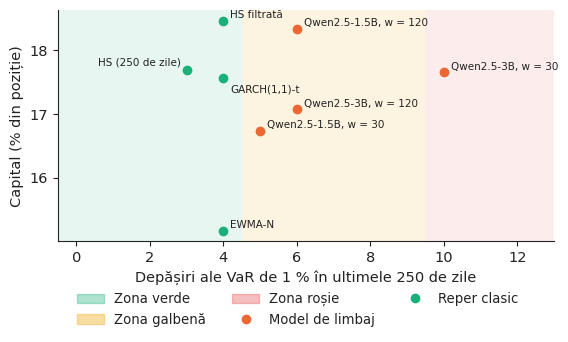

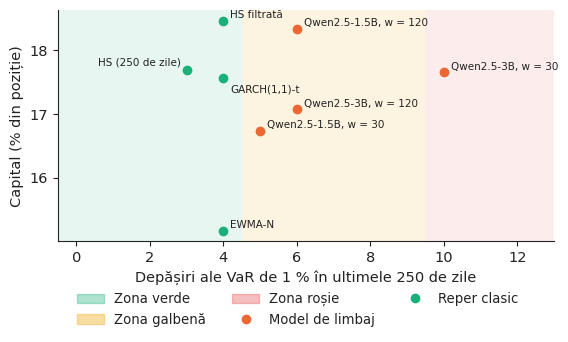

In [11]:
cap = {}
for nm, f in MODELS.items():
    v = -f["q0.01"].values
    k = plus(int((y < f["q0.01"].values)[-250:].sum()))
    cap[nm] = {"k": k, "capital": (3 + k) * v[-60:].mean() * np.sqrt(10), "x250": int((y < f["q0.01"].values)[-250:].sum())}
cap = pd.DataFrame(cap).T.astype(float)
print(cap.round(2))
ZC = {"green": "#1baf7a", "yellow": "#eda100", "red": "#e34948"}
cap_order = [o for o in order if not o.endswith("chat")]            # the chat prompt (red zone, far right) is reported in the table only
OFF = {"HS (250 days)": (-4, 3, "right"), "GARCH(1,1)-t": (5, -10, "left")}
def fig_cap(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.0))
    xmax = max(13, cap.loc[cap_order, "x250"].max() + 2)
    ax.axvspan(-0.5, 4.5, color=ZC["green"], alpha=0.10, lw=0); ax.axvspan(4.5, 9.5, color=ZC["yellow"], alpha=0.12, lw=0)
    ax.axvspan(9.5, xmax, color=ZC["red"], alpha=0.10, lw=0)
    for nm in cap_order:
        ax.scatter(cap.loc[nm, "x250"], cap.loc[nm, "capital"], s=36, color=C_LLM if nm.startswith("LLM") else C_BM, zorder=3)
        dx, dy, ha = OFF.get(nm, (5, 2, "left"))
        ax.annotate(cu.T(lang, *LAB[nm]).replace("LLM-VaR ", ""), (cap.loc[nm, "x250"], cap.loc[nm, "capital"]), fontsize=7.5,
                    xytext=(dx, dy), textcoords="offset points", ha=ha)
    ax.set_xlim(-0.5, xmax)
    ax.set_xlabel(cu.T(lang, "1 % VaR violations in the last 250 days", "Depășiri ale VaR de 1 % în ultimele 250 de zile"))
    ax.set_ylabel(cu.T(lang, "Capital (% of the position)", "Capital (% din poziție)"))
    cu.comma_axis(ax, lang)
    from matplotlib.patches import Patch
    hd = [Patch(color=ZC[z_], alpha=0.35) for z_ in ("green", "yellow", "red")] + [plt.Line2D([], [], marker="o", ls="", color=C_LLM), plt.Line2D([], [], marker="o", ls="", color=C_BM)]
    lb = [cu.T(lang, "Green zone", "Zona verde"), cu.T(lang, "Yellow zone", "Zona galbenă"), cu.T(lang, "Red zone", "Zona roșie"),
          cu.T(lang, "Language model", "Model de limbaj"), cu.T(lang, "Classical benchmark", "Reper clasic")]
    cu.legend_bottom(fig, ncol=3, handles=hd, labels=lb)
    return fig
cu.save_both(fig_cap, "f4_capital")

## 7. Cifrele pentru studiul de caz

In [12]:
best_llm = res.loc[[m for m in order if m.startswith("LLM")], "fz"].astype(float).idxmin()
lm_rows = [m for m in order if m.startswith("LLM") and not m.endswith("chat")]
mm, rf = res.loc[MAIN], res.loc[REF]
corr = float(np.corrcoef(f_main["q0.01"], f_ref["q0.01"])[0, 1])
nm_ro = lambda s: s.replace("w = ", "w = ")
N = {
    "nTest": int(n_test), "testStart": (f"{TD[0].day} {TD[0]:%B %Y}", f"{TD[0]:%d.%m.%Y}"), "testEnd": (f"{TD[-1].day} {TD[-1]:%B %Y}", f"{TD[-1]:%d.%m.%Y}"),
    "expOne": 0.01 * n_test, "expTwo": 0.025 * n_test,
    "mViol": int(mm.viol), "mRate": mm.rate, "mPuc": mm.puc, "mPcc": mm.pcc, "mVar": mm["var"], "mFz": mm.fz, "mDm": mm.dm, "mDmp": mm.dmp, "mXtf": int(mm.x250),
    "gViol": int(rf.viol), "gRate": rf.rate, "gPuc": rf.puc, "gPcc": rf.pcc, "gVar": rf["var"], "gFz": rf.fz, "gXtf": int(rf.x250),
    "hViol": int(res.loc["HS (250 days)", "viol"]), "eViol": int(res.loc["EWMA-N", "viol"]), "fViol": int(res.loc["Filtered HS", "viol"]),
    "sViol": int(res.loc["LLM-VaR Qwen2.5-1.5B, w = 30", "viol"]), "sViolL": int(res.loc["LLM-VaR Qwen2.5-1.5B, w = 120", "viol"]),
    "bViolL": int(res.loc["LLM-VaR Qwen2.5-3B, w = 120", "viol"]),
    "llmViolMin": int(res.loc[lm_rows, "viol"].min()), "llmViolMax": int(res.loc[lm_rows, "viol"].max()),
    "bmViolMin": int(res.loc[list(BM), "viol"].min()), "bmViolMax": int(res.loc[list(BM), "viol"].max()),
    "bestLlm": (best_llm.replace("LLM-VaR ", ""), best_llm.replace("LLM-VaR ", "")), "bestLlmFz": res.loc[best_llm, "fz"],
    "bestBm": (res.loc[list(BM), "fz"].astype(float).idxmin(), LAB[res.loc[list(BM), "fz"].astype(float).idxmin()][1]),
    "bestBmFz": res.loc[list(BM), "fz"].min(),
    "corrMain": corr, "sdLlm": LLM[("Qwen2.5-3B", 30, "text")]["sd"].mean(), "sdChat": LLM[("Qwen2.5-3B", 30, "chat")]["sd"].mean(),
    "cViol": int(res.loc["LLM-VaR Qwen2.5-3B, w = 30, chat", "viol"]), "cRate": res.loc["LLM-VaR Qwen2.5-3B, w = 30, chat", "rate"], "sdReal": float(r.loc[TD].std()),
    "exDate": (f"{d_ex.day} {d_ex:%B %Y}", f"{d_ex:%d.%m.%Y}"), "exRet": float(r.loc[d_ex]), "exLlm": float(np.quantile(smp, 0.01)), "exGarch": float(g["gt_q0.01"]),
    "capM": cap.loc[MAIN, "capital"], "capG": cap.loc[REF, "capital"], "kM": cap.loc[MAIN, "k"], "kG": cap.loc[REF, "k"],
    "zM": (res.loc[MAIN, "zone"], {"green": "verde", "yellow": "galbenă", "red": "roșie"}[res.loc[MAIN, "zone"]]),
    "zG": (res.loc[REF, "zone"], {"green": "verde", "yellow": "galbenă", "red": "roșie"}[res.loc[REF, "zone"]]),
    "nuMean": float(G["nu"].mean()),
    "cEsPos": int((LLM[("Qwen2.5-3B", 30, "chat")]["es0.025"] >= 0).sum()), "cMean": LLM[("Qwen2.5-3B", 30, "chat")]["mean"].mean(),
    "tMean": LLM[("Qwen2.5-3B", 30, "text")]["mean"].mean(), "rMean": float(r.loc[TD].mean()),
    "sTwo": res.loc["LLM-VaR Qwen2.5-1.5B, w = 30", "rate25"], "sTwoL": res.loc["LLM-VaR Qwen2.5-1.5B, w = 120", "rate25"],
    "bTwo": res.loc["LLM-VaR Qwen2.5-3B, w = 30", "rate25"], "bTwoL": res.loc["LLM-VaR Qwen2.5-3B, w = 120", "rate25"],
    "hPuc": res.loc["HS (250 days)", "puc"], "fPuc": res.loc["Filtered HS", "puc"], "sDmp": res.loc["LLM-VaR Qwen2.5-1.5B, w = 30", "dmp"], "sFz": res.loc["LLM-VaR Qwen2.5-1.5B, w = 30", "fz"],
}
cu.write_numbers(N, digits={"expOne": 1, "expTwo": 1, "mRate": 2, "mPuc": 3, "mPcc": 3, "mVar": 2, "mFz": 3, "mDm": 2, "mDmp": 3,
                            "gRate": 2, "gPuc": 3, "gPcc": 3, "gVar": 2, "gFz": 3, "bestLlmFz": 3, "bestBmFz": 3, "corrMain": 2, "sdLlm": 2, "sdReal": 2,
                            "exRet": 2, "exLlm": 2, "sdChat": 2, "cRate": 2, "exGarch": 2, "capM": 2, "capG": 2, "kM": 2, "kG": 2, "nuMean": 1, "cMean": 2, "tMean": 2, "rMean": 2, "sTwo": 2, "sTwoL": 2, "bTwo": 2, "bTwoL": 2, "hPuc": 3, "fPuc": 3, "sDmp": 3, "sFz": 3})
print(json.dumps(json.load(open("numbers.json")), indent=1, ensure_ascii=False))

{
 "nTest": 505,
 "testStart": "1 November 2024",
 "testEnd": "6 November 2026",
 "expOne": 5.05,
 "expTwo": 12.625,
 "mViol": 16,
 "mRate": 3.168317,
 "mPuc": 9.4e-05,
 "mPcc": 0.0004,
 "mVar": 2.013322,
 "mFz": 1.426524,
 "mDm": 1.66465,
 "mDmp": 0.095983,
 "mXtf": 10,
 "gViol": 11,
 "gRate": 2.178218,
 "gPuc": 0.021347,
 "gPcc": 0.034336,
 "gVar": 2.283724,
 "gFz": 1.214424,
 "gXtf": 4,
 "hViol": 8,
 "eViol": 11,
 "fViol": 10,
 "sViol": 11,
 "sViolL": 12,
 "bViolL": 13,
 "llmViolMin": 11,
 "llmViolMax": 16,
 "bmViolMin": 8,
 "bmViolMax": 11,
 "bestLlm": "Qwen2.5-1.5B, w = 120",
 "bestLlmFz": 1.33358,
 "bestBm": "Filtered HS",
 "bestBmFz": 1.15822,
 "corrMain": 0.88725,
 "sdLlm": 0.863083,
 "sdChat": 0.962424,
 "cViol": 64,
 "cRate": 12.673267,
 "sdReal": 1.029951,
 "exDate": "4 April 2025",
 "exRet": -6.160906,
 "exLlm": -4.872475,
 "exGarch": -4.50234,
 "capM": 17.655175,
 "capG": 17.56006,
 "kM": 1.0,
 "kG": 0.0,
 "zM": "red",
 "zG": "green",
 "nuMean": 7.413748,
 "cEsPos": 62,
 "

In [13]:
# slide-ready summary for a lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=2: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{LLM-VaR and LLM-ES} (Pele et al., 2026, Expert Systems with Applications): GPT models continue the return series zero-shot; short windows work best, GPT-3.5 matches newer models.",
          "\\textbf{LLM-VaR și LLM-ES} (Pele et al., 2026, Expert Systems with Applications): modelele GPT continuă seria randamentelor fără antrenare; ferestrele scurte dau cele mai bune rezultate, iar GPT-3.5 egalează modelele mai noi."),
        t(f"Our replication: Qwen2.5-3B on a laptop, S\\&P 500, {n_test} test days: {int(mm.viol)} violations of the 1\\,\\% LLM-VaR (expected {F(0.01 * n_test, 1)}); GARCH(1,1)-$t$: {int(rf.viol)}.",
          f"Replicarea noastră: Qwen2.5-3B pe un laptop, S\\&P 500, {n_test} de zile de test: {int(mm.viol)} depășiri ale LLM-VaR de 1\\,\\% (așteptate {F(0.01 * n_test, 1)}); GARCH(1,1)-$t$: {int(rf.viol)}."),
        t(f"Joint VaR--ES accuracy (FZ0 loss): best language model {F(res.loc[best_llm, 'fz'], 3)}, GARCH(1,1)-$t$ {F(rf.fz, 3)} (lower is better).",
          f"Acuratețea comună VaR--ES (pierderea FZ0): cel mai bun model de limbaj {F(res.loc[best_llm, 'fz'], 3)}, GARCH(1,1)-$t$ {F(rf.fz, 3)} (mai mic este mai bine)."),
        t("Decision: a risk model is judged by its backtest and by the capital it implies, not by the size of the network.",
          "Decizia: un model de risc se judecă după testarea retrospectivă și după capitalul pe care îl implică, nu după dimensiunea rețelei."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{LLM-VaR and LLM-ES} (Pele et al., 2026, Expert Systems with Applications): GPT models continue the return series zero-shot; short windows work best, GPT-3.5 matches newer models.
  \item Our replication: Qwen2.5-3B on a laptop, S\&P 500, 505 test days: 16 violations of the 1\,\% LLM-VaR (expected 5.0); GARCH(1,1)-$t$: 11.
  \item Joint VaR--ES accuracy (FZ0 loss): best language model 1.334, GARCH(1,1)-$t$ 1.214 (lower is better).
  \item Decision: a risk model is judged by its backtest and by the capital it implies, not by the size of the network.
\end{itemize}



## Exerciții suplimentare
1. Schimbați fereastra de la 30 la 60 și 90 de zile (lucrarea folosește și 45, 60, 90, 120 și 150). Se modifică frecvența depășirilor în direcția raportată în lucrare pentru ferestrele lungi?
2. Fixați temperatura la 1,0 și la 0,3. Cum se modifică lățimea distribuției eșantionate și frecvența depășirilor și de ce?
3. Înlocuiți indicele S&P 500 cu Bitcoin (`BTCUSD` în `markets_daily.csv`; lucrarea arată că LLM-urile sînt utile pe piețele volatile ale criptomonedelor). Comparați din nou LLM-VaR cu GARCH(1,1)-t.